In [29]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import opt_einsum   

from ngo.ml.torch_utils import torch_repeat

In [30]:
class BSpline:
    """
    B-spline basis functions with vectorized evaluation and differentiation using PyTorch.
    """
    def __init__(self, N, p, C, dtype, device):
        """""
        Initialize the B-spline basis.

        Args:
            N: Number of basis functions.
            p: Degree of the B-splines.
            C: Continuity at internal knots (C < p).
            dtype: Torch data type for computations.
            device: Torch device for computations.
        """
        self.dtype = dtype
        self.device = device
        self.N = N
        self.p = p
        self.C = C
        self.knot_vector = torch.zeros(self.p+1, dtype=self.dtype, device=self.device)
        self.knot_vector = torch.cat((
            self.knot_vector,
            torch_repeat(
                torch.linspace(
                    0, 1,
                    int((self.N - self.p - 1)/(self.p - self.C)) + 2,
                    dtype=self.dtype, device=self.device
                )[1:-1],
                self.p - self.C
            )
        ))
        self.knot_vector = torch.cat((self.knot_vector, torch.ones(self.p+1, dtype=self.dtype, device=self.device)))

    def _basis_dp(self, x: torch.Tensor, return_prev: bool = False):
        """
        Vectorized Cox–de Boor evaluation for all basis functions in parallel.

        Args:
            x: 1D tensor of evaluation points, shape (Q,).
            return_prev: If True, also returns I_{*,p-1}(x) for derivative.

        Returns:
            I_p: (N, Q) values of I_{i,p}(x).
            I_pm1: (N, Q) values of I_{i,p-1}(x) if return_prev=True, else None.
        """
        t = self.knot_vector
        x = x.to(dtype=self.dtype, device=self.device)
        N, p = self.N, self.p

        # Degree-0 indicator functions: [t_i, t_{i+1}) except last interval includes right endpoint
        t_i = t[:N].unsqueeze(1)       # (N,1)
        t_ip1 = t[1:N+1].unsqueeze(1)  # (N,1)
        
        # Use half-open intervals [t_i, t_{i+1})
        I = (t_i <= x) & (x < t_ip1)  # (N,Q) boolean
        
        # Special case: include right endpoint for the last interval
        I[-1] = I[-1] | (x == t_ip1[-1])
        
        # Convert to float after logical operations
        I = I.to(self.dtype)

        if p == 0:
            return (I, None) if return_prev else I

        # Iteratively raise degree to p
        for r in range(1, p+1):
            den1 = (t[r:r+N] - t[:N]).unsqueeze(1)          # (N,1)
            den2 = (t[r+1:r+1+N] - t[1:N+1]).unsqueeze(1)   # (N,1)

            # Shift I for i+1 term
            I_ip1 = torch.cat([I[1:], torch.zeros_like(I[:1])], dim=0)

            # Weights with safe division
            w1 = torch.where(den1 > 0, (x - t[:N].unsqueeze(1)) / den1, torch.zeros_like(I))
            w2 = torch.where(den2 > 0, (t[r+1:r+1+N].unsqueeze(1) - x) / den2, torch.zeros_like(I))

            if return_prev and r == p:
                I_prev = I  # save I_{*,p-1}
            I = w1 * I + w2 * I_ip1

        return (I, I_prev) if return_prev else I

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Evaluate all B-spline basis functions I_{i,p}(x) in parallel.

        Args:
            x: 1D tensor of points, shape (Q,).

        Returns:
            (N, Q) tensor with I_{i,p}(x).
        """
        return self._basis_dp(x)

    def grad(self, x: torch.Tensor) -> torch.Tensor:
        """
        Evaluate derivatives d/dx I_{i,p}(x) for all i in parallel.

        Args:
            x: 1D tensor of points, shape (Q,).

        Returns:
            (N, Q) tensor with d/dx I_{i,p}(x).
        """
        I_p, I_pm1 = self._basis_dp(x, return_prev=True)
        N, p = self.N, self.p
        if p == 0:
            return torch.zeros_like(I_p)

        t = self.knot_vector
        den1 = (t[p:p+N] - t[:N]).unsqueeze(1)          # (N,1)
        den2 = (t[p+1:p+1+N] - t[1:N+1]).unsqueeze(1)   # (N,1)

        term1 = torch.where(den1 > 0, (p / den1) * I_pm1, torch.zeros_like(I_pm1))
        I_pm1_ip1 = torch.cat([I_pm1[1:], torch.zeros_like(I_pm1[:1])], dim=0)
        term2 = torch.where(den2 > 0, (p / den2) * I_pm1_ip1, torch.zeros_like(I_pm1))

        return term1 - term2

In [31]:
x = torch.linspace(0, 1, 1000, dtype=torch.float32, device='cuda')

In [42]:
basis = BSpline(N=10, p=0, C=-1, dtype=torch.float32, device='cuda')

In [43]:
y = basis.forward(x)

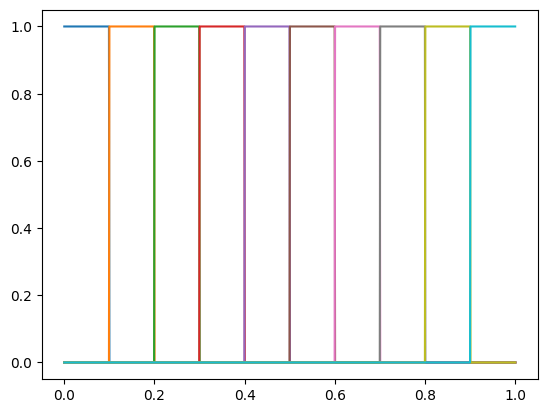

In [44]:
for i in range(basis.N):
    plt.plot(x.cpu(), y[i, :].cpu(), label=f'N_{i},{basis.p}')

In [7]:
y = basis.grad(x)

In [8]:
for i in range(basis.n):
    plt.plot(x.cpu(), y[i, :].cpu(), label=f'N_{i},{basis.p}')

AttributeError: 'BSpline' object has no attribute 'n'